# import

In [2]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import dbetto
import lh5
import pandas as pd
import pygeomhades
import pygeomtools
from pygeomtools import write_pygeom
import pyg4ometry as pg4
from pyg4ometry import gdml
from pathlib import Path
from copy import deepcopy


from scipy.optimize import least_squares
from scipy.special import erf, erfc, xlogy
from scipy.stats import exponnorm

%matplotlib inline


# configuration
§

In [3]:
detector = "V06643A"
version = "v1.2.1"

measure = "am_HS1_top_ssh"
run = 1
campaign = "c1"



In [4]:
metadata_path = "/global/u2/r/ritaferi/HADES_DATA/hades-metadata"
db = dbetto.TextDB(metadata_path)


In [5]:
db_data = db.hardware.configuration[detector]["c1"][measure]['run0001']

# data

In [6]:
run = 1
run_tag = f'r000{run}'
run_key = f'r00{run}'
run_meta = f'run000{run}'

In [11]:
detector

'V06643A'

In [12]:
file_pattern = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/{measure}/*.lh5"
)

file_names = sorted(glob.glob(file_pattern))

In [13]:
if not file_names:
    raise FileNotFoundError(
        f"Nessun file trovato per {detector}, {measure}, {run_key}:\n"
        f"{file_pattern}"
    )

print(f"{run_key}: {len(file_names)} file trovati")



r001: 284 file trovati


In [14]:
file_names = sorted(glob.glob(file_pattern))

In [15]:
if not file_names:
    raise FileNotFoundError(
        f"Nessun file trovato per {detector}, {measure}, {run_tag}:\n"
        f"{file_pattern}"
    )

print(f"{run_tag}: {len(file_names)} file trovati")


r0001: 284 file trovati


In [16]:
meta_data = (
    db.hardware.configuration[detector]
    [campaign][measure][run_meta]
)


In [17]:
db.hardware.configuration[detector][campaign][measure][run_meta]

{'campaign': 'c1',
 'daq_settings': {'flashcam': {'card_interface': 'efb3',
   'decay_time_in_ns': 46000,
   'shaping_time_in_ns': 6000,
   'signal_depth_in_samples': 22290,
   'trigger_threshold': 1400}},
 'detector': 'V06643A',
 'elog': 'https://elog.legend-exp.org/HADES/311',
 'high_voltage_in_V': 2800,
 'measurement': 'am_HS1_top_ssh',
 'run': 'run0001',
 'run_live_time_in_s': 300,
 'run_start_time': '221118T203210',
 'shifter': 'Simon',
 'source_position': {'phi_in_deg': 0.0, 'r_in_mm': 34.0, 'z_in_mm': 4.0}}

In [18]:
import re
config = db.hardware.configuration[detector][campaign][measure]

runs = sorted(
    (key for key in config if re.fullmatch(r"run\d+", key)),
    key=lambda key: int(key[3:]),
)

coordinates = {
    "r_in_mm": [],
    "z_in_mm": [],
    "phi_in_deg": [],
}
for run in runs:
    position = config[run].get("source_position") or {}

    for key in coordinates:
        try:
            value = float(position[key])
        except (KeyError, TypeError, ValueError):
            value = np.nan

        coordinates[key].append(
            value if np.isfinite(value) else np.nan
        )


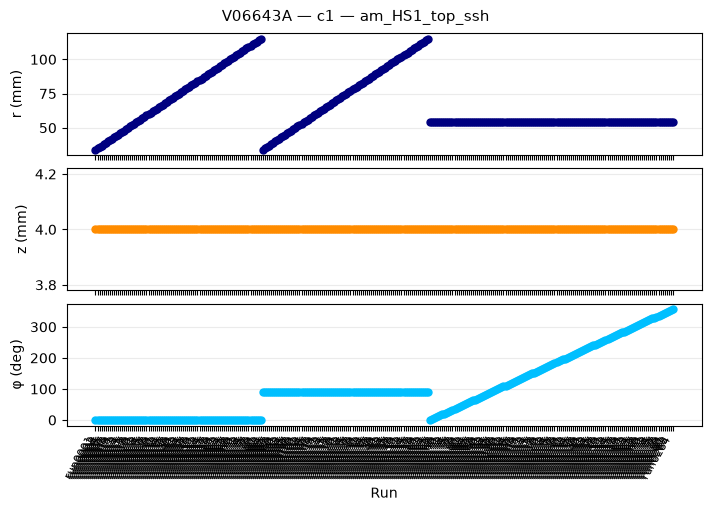

In [19]:

x = np.arange(len(runs))

fig, axes = plt.subplots(
    3,
    1,
    figsize=(7, 5),
    sharex=True,
    #dpi=200,
    layout="constrained",
)

settings = [
    ("r_in_mm", "r (mm)", "navy"),
    ("z_in_mm", "z (mm)", "darkorange"),
    ("phi_in_deg", "φ (deg)", "deepskyblue"),
]

for ax, (key, label, color) in zip(axes, settings):
    ax.plot(
        x,
        coordinates[key],
        marker="o",
        linestyle="none",
        color=color,
        markersize=5,
    )

    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.25)

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(
    runs,
    rotation=60,
    ha="right",
    fontsize=8,
)
axes[-1].set_xlabel("Run")

fig.suptitle(
    f"{detector} — {campaign} — {measure}",
    fontsize=11,
)

plt.show()

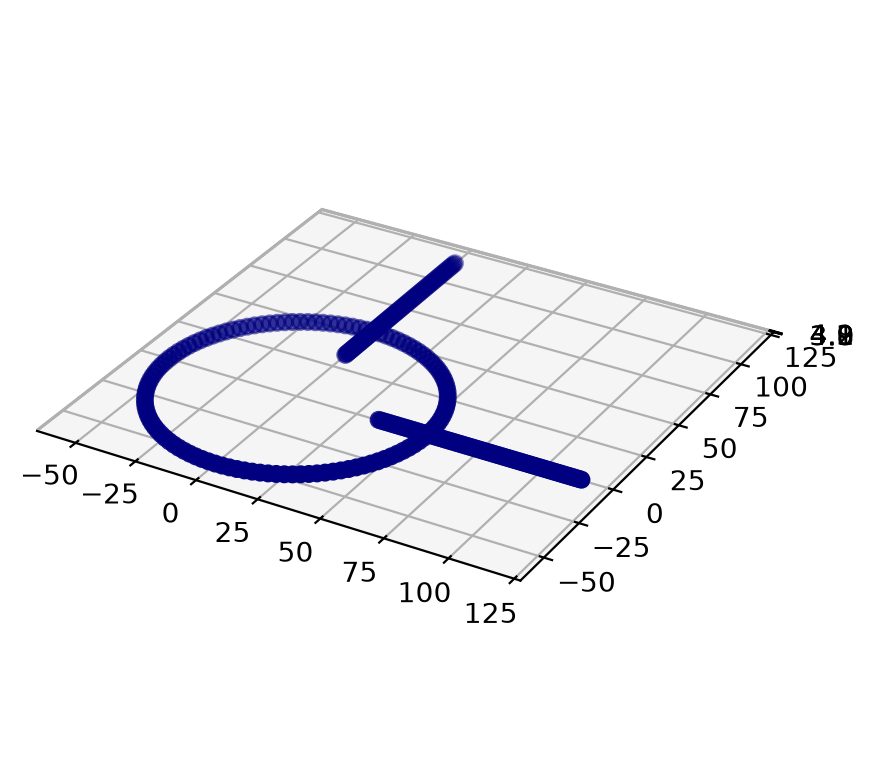

In [20]:
import re
import numpy as np
import matplotlib.pyplot as plt

config = db.hardware.configuration[detector][campaign][measure]

runs = sorted(
    (key for key in config if re.fullmatch(r"run\d+", key)),
    key=lambda key: int(key[3:]),
)

positions = []

for run in runs:
    try:
        pos = config[run]["source_position"]

        values = [
            float(pos["r_in_mm"]),
            float(pos["phi_in_deg"]),
            float(pos["z_in_mm"]),
        ]

        if np.isfinite(values).all():
            positions.append(values)

    except (KeyError, TypeError, ValueError):
        continue

if not positions:
    raise ValueError("Nessuna posizione valida.")

r, phi, z = np.asarray(positions).T

# Coordinate cilindriche → cartesiane.
x = r * np.cos(np.deg2rad(phi))
y = r * np.sin(np.deg2rad(phi))

fig = plt.figure(figsize=(5, 4), dpi=200)
ax = fig.add_subplot(111, projection="3d")

ax.scatter(x, y, z, color="navy", s=30)
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [21]:
hit = lh5.read(
            "hit",
            file_names,
        )


In [22]:
hit.keys()

dict_keys(['AoE_Classifier', 'AoE_Corrected', 'AoE_Double_Sided_Cut', 'AoE_High_Side_Cut', 'AoE_Low_Cut', 'LQ_Classifier', 'LQ_Cut', 'bl_pileup_cut', 'bl_pileup_cut_classifier', 'cuspEmax_cal', 'cuspEmax_ctc_cal', 'cuspEmax_noctc_cal', 'daqenergy_cal', 'dt_eff', 'is_discharge', 'is_downgoing_baseline', 'is_empty_candidate', 'is_highly_positive_polarity_candidate', 'is_low_cuspEmax', 'is_neg_energy', 'is_negative', 'is_negative_crosstalk_old', 'is_negative_polarity_candidate', 'is_noise_burst', 'is_not_noise_burst', 'is_positive_polarity_candidate', 'is_saturated', 'is_surface', 'is_upgoing_baseline', 'is_valid_0vbb_old', 'is_valid_baseline_old', 'is_valid_bl_slope', 'is_valid_bl_slope_classifier', 'is_valid_bl_slope_rms', 'is_valid_bl_slope_rms_classifier', 'is_valid_cal', 'is_valid_cuspEmax', 'is_valid_cuspEmax_classifier', 'is_valid_cuspEmin', 'is_valid_cuspEmin_classifier', 'is_valid_dteff', 'is_valid_dteff_old', 'is_valid_ediff', 'is_valid_efrac', 'is_valid_neg_current', 'is_valid_

In [23]:
ene_raw = np.asarray(
            hit["cuspEmax_ctc_cal"].nda
        )

In [24]:
is_discharge = np.asarray(
            hit["is_discharge"].nda,
            dtype=bool,
        )


is_not_noise_burst = np.asarray(
            hit["is_not_noise_burst"].nda,
            dtype=bool,
        )
is_positive_polarity = np.asarray(
            hit["is_positive_polarity_candidate"].nda,
            dtype=bool,
        )
finite = np.isfinite(ene_raw)
is_positive = (ene_raw > 0)

mask = (
            finite
            & ~is_discharge
            & is_positive_polarity 
    & is_not_noise_burst
            & is_positive
        )

In [25]:
ene = ene_raw[mask]

(-10.0, 3000.0)

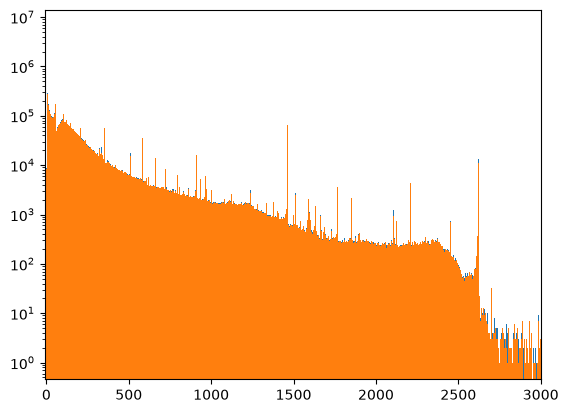

In [26]:
plt.hist(ene_raw, 3000, range = (-50, 3000))
c, be, _ = plt.hist(ene, 3000, range = (0, 3000))
plt.yscale('log')
plt.xlim(-10, 3000)

In [27]:
np.sum(c)

np.float64(31676983.0)

# scan

In [28]:
from pathlib import Path
import re

import lh5
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# CONFIGURATION
# Usa detector, campaign, measure, version e db già definiti.
# ============================================================

energy_range = (0.0, 3000.0)

hit_root = (
    Path("/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref")
    / version
    / "generated"
    / "tier"
    / "hit"
)

# Gruppi corrispondenti all'elenco dei tuoi 284 run.
scan_run_ranges = {
    "radial_phi0": (1, 82),
    "radial_phi90": (83, 164),
    "angular": (165, 284),
}

config = db.hardware.configuration[detector][campaign][measure]

runs = sorted(
    (
        key for key in config
        if re.fullmatch(r"run\d+", key)
    ),
    key=lambda key: int(key[3:]),
)


def get_scan(run):
    number = int(run[3:])

    for scan, (first, last) in scan_run_ranges.items():
        if first <= number <= last:
            return scan

    return None


# Risultati disponibili anche dopo aver eseguito la cella.
scan_results = {}


# ============================================================
# COUNT QC EVENTS IN ALL FILES OF EACH RUN
# ============================================================

for run in runs:
    scan = get_scan(run)

    if scan is None:
        continue

    try:
        meta = config[run]
        pos = meta["source_position"]

        r = float(pos["r_in_mm"])
        z = float(pos["z_in_mm"])
        phi = float(pos["phi_in_deg"])

        live_time = float(meta["run_live_time_in_s"])

        if (
            not np.isfinite([r, z, phi, live_time]).all()
            or live_time <= 0
        ):
            raise ValueError("Posizione o live time non validi.")

        run_tag = f"r{int(run[3:]):03d}"

        folder = hit_root / detector / campaign / measure

        files = sorted(folder.glob(
            f"char_data-{detector}-{measure}-"
            f"{run_tag}-*-tier_hit.lh5"
        ))

        if not files:
            raise FileNotFoundError("Nessun file LH5 trovato.")

        total_counts = 0

        print(
            f"{detector}/{run} | {scan} | "
            f"files={len(files)} | live time={live_time:g} s",
            flush=True,
        )

        for filename in files:
            hit = lh5.read("hit", str(filename))

            ene_raw = np.asarray(
                hit["cuspEmax_ctc_cal"].nda,
                dtype=float,
            )

            is_discharge = np.asarray(
                hit["is_discharge"].nda,
                dtype=bool,
            )

            is_not_noise_burst = np.asarray(
                hit["is_not_noise_burst"].nda,
                dtype=bool,
            )

            is_positive_polarity = np.asarray(
                hit["is_positive_polarity_candidate"].nda,
                dtype=bool,
            )

            flags = (
                is_discharge,
                is_not_noise_burst,
                is_positive_polarity,
            )

            if (
                ene_raw.ndim != 1
                or any(flag.shape != ene_raw.shape for flag in flags)
            ):
                raise ValueError(
                    f"Dimensioni energia/flag incompatibili: {filename}"
                )

            mask = (
                np.isfinite(ene_raw)
                & (~is_discharge)
                & is_positive_polarity
                & is_not_noise_burst
                & (ene_raw > 0)
            )

            # Equivalente alla somma dell'istogramma in 0–3000 keV.
            # Il bordo superiore è incluso, come in np.histogram.
            in_range = (
                (ene_raw >= energy_range[0])
                & (ene_raw <= energy_range[1])
            )

            total_counts += int(np.count_nonzero(mask & in_range))

            del hit, ene_raw, flags
            del is_discharge, is_not_noise_burst
            del is_positive_polarity, mask, in_range

        rate = total_counts / live_time
        rate_error = np.sqrt(total_counts) / live_time

        scan_results[run] = {
            "scan": scan,
            "r_in_mm": r,
            "z_in_mm": z,
            "phi_in_deg": phi,
            "counts": total_counts,
            "live_time_s": live_time,
            "rate_per_s": rate,
            "rate_error_per_s": rate_error,
            "n_files": len(files),
        }

        print(
            f"  N={total_counts:,} | "
            f"rate={rate:.4g} ± {rate_error:.3g} counts/s",
            flush=True,
        )

    except Exception as exc:
        # Non usa un conteggio parziale se un file del run fallisce.
        print(
            f"Skipping {detector}/{run}: "
            f"{type(exc).__name__}: {exc}",
            flush=True,
        )


V06643A/run0001 | radial_phi0 | files=1 | live time=300 s
  N=74,366 | rate=247.9 ± 0.909 counts/s
V06643A/run0002 | radial_phi0 | files=1 | live time=300 s
  N=82,831 | rate=276.1 ± 0.959 counts/s
V06643A/run0003 | radial_phi0 | files=1 | live time=300 s
  N=98,255 | rate=327.5 ± 1.04 counts/s
V06643A/run0004 | radial_phi0 | files=1 | live time=300 s
  N=109,550 | rate=365.2 ± 1.1 counts/s
V06643A/run0005 | radial_phi0 | files=1 | live time=300 s
  N=113,966 | rate=379.9 ± 1.13 counts/s
V06643A/run0006 | radial_phi0 | files=1 | live time=300 s
  N=115,276 | rate=384.3 ± 1.13 counts/s
V06643A/run0007 | radial_phi0 | files=1 | live time=300 s
  N=115,174 | rate=383.9 ± 1.13 counts/s
V06643A/run0008 | radial_phi0 | files=1 | live time=300 s
  N=115,660 | rate=385.5 ± 1.13 counts/s
V06643A/run0009 | radial_phi0 | files=1 | live time=300 s
  N=116,786 | rate=389.3 ± 1.14 counts/s
V06643A/run0010 | radial_phi0 | files=1 | live time=300 s
  N=117,935 | rate=393.1 ± 1.14 counts/s
V06643A/run0

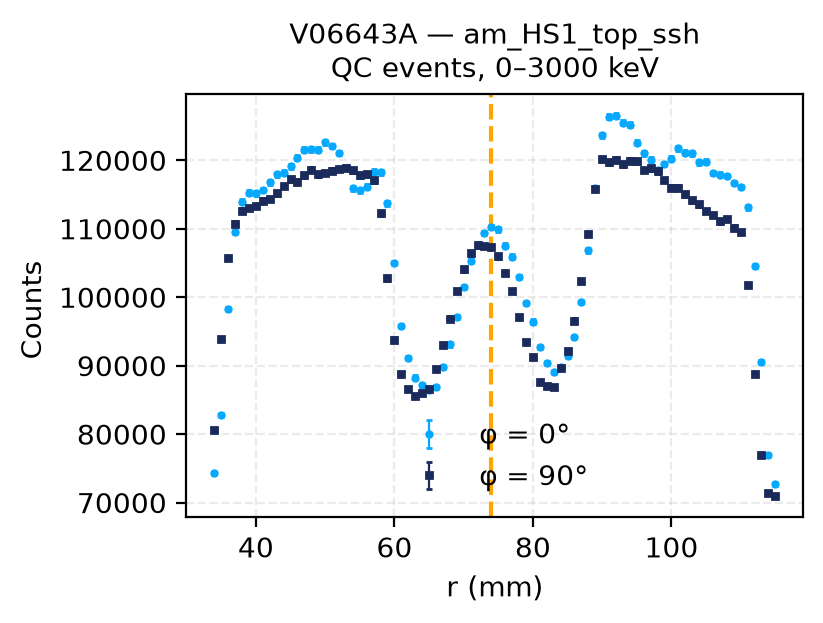

In [34]:


# ============================================================
# PLOT 1 — RADIAL SCANS AT PHI = 0° AND 90°
# ============================================================

fig, ax = plt.subplots(
    figsize=(4,3),
    dpi=200,
    layout="constrained",
)

radial_styles = {
    "radial_phi0": ("#07A9FF", "o", "φ = 0°"),
    "radial_phi90": ("#1A2A5B", "s", "φ = 90°"),
}

has_radial_data = False

for scan, (color, marker, label) in radial_styles.items():
    selected = sorted(
        (
            item for item in scan_results.values()
            if item["scan"] == scan
        ),
        key=lambda item: item["r_in_mm"],
    )

    if not selected:
        continue

    has_radial_data = True

    ax.errorbar(
        [item["r_in_mm"] for item in selected],
        [item["rate_per_s"]*300 for item in selected],
        yerr=[item["rate_error_per_s"]*300 for item in selected],
        fmt=marker,
        linestyle="none",
        color=color,
        ecolor=color,
        markersize=2,
        capsize=1,
        elinewidth=0.8,
        label=label,
    )

ax.set_xlabel("r (mm)")
ax.set_ylabel("Counts ")
ax.set_title(
    f"{detector} — {measure}\n"
    f"QC events, {energy_range[0]:g}–{energy_range[1]:g} keV",
    fontsize=10,
)
ax.grid(alpha=0.25, linestyle="--")

if has_radial_data:
    ax.legend(frameon=False)
else:
    ax.text(
        0.5, 0.5,
        "No radial scan data",
        transform=ax.transAxes,
        ha="center",
    )
ax.axvline(74, color = 'orange', ls = '--')
plt.show()



In [30]:
'''
# ============================================================
# PLOT 2 — ANGULAR SCAN AT CONSTANT R
# ============================================================

angular = sorted(
    (
        item for item in scan_results.values()
        if item["scan"] == "angular"
    ),
    key=lambda item: item["phi_in_deg"],
)

if angular:
    r_values = np.array([item["r_in_mm"] for item in angular])

    if not np.allclose(r_values, r_values[0]):
        print(
            "Attenzione: r non è costante nello scan angolare. "
            f"Intervallo: {r_values.min():g}–{r_values.max():g} mm."
        )

    fig, ax = plt.subplots(
        figsize=(8,5),
        dpi=200,
        layout="constrained",
    )

    ax.errorbar(
        [item["phi_in_deg"] for item in angular],
        [item["rate_per_s"] for item in angular],
        yerr=[item["rate_error_per_s"] for item in angular],
        fmt="o",
        linestyle="none",
        color="#07A9FF",
        ecolor="#07A9FF",
        markersize=2,
        capsize=2,
        elinewidth=0.8,
    )

    ax.set_xlabel("φ (deg)")
    ax.set_ylabel("Counts / s")
    ax.set_xticks(np.arange(0, 361, 45))

    r_text = (
        f"r = {r_values[0]:g} mm"
        if np.allclose(r_values, r_values[0])
        else f"r = {r_values.min():g}–{r_values.max():g} mm"
    )

    ax.set_title(
        f"{detector} — {measure}\n{r_text} — QC events",
        fontsize=10,
    )

    ax.grid(alpha=0.25, linestyle="--")

    plt.show()

else:
    print("Nessun dato disponibile per lo scan angolare.")'''

'\n# ============================================================\n# PLOT 2 — ANGULAR SCAN AT CONSTANT R\n# ============================================================\n\nangular = sorted(\n    (\n        item for item in scan_results.values()\n        if item["scan"] == "angular"\n    ),\n    key=lambda item: item["phi_in_deg"],\n)\n\nif angular:\n    r_values = np.array([item["r_in_mm"] for item in angular])\n\n    if not np.allclose(r_values, r_values[0]):\n        print(\n            "Attenzione: r non è costante nello scan angolare. "\n            f"Intervallo: {r_values.min():g}–{r_values.max():g} mm."\n        )\n\n    fig, ax = plt.subplots(\n        figsize=(8,5),\n        dpi=200,\n        layout="constrained",\n    )\n\n    ax.errorbar(\n        [item["phi_in_deg"] for item in angular],\n        [item["rate_per_s"] for item in angular],\n        yerr=[item["rate_error_per_s"] for item in angular],\n        fmt="o",\n        linestyle="none",\n        color="#07A9FF",\n     